In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from deep_isochron.analysis.ode import (
    find_limit_cycle,
    floquet,
    isochron_foliation,
    IsochronSettings,
)
from deep_isochron.data import (
    resolve_device,
)
from deep_isochron.plotting import configure_rcparams, plot_isochrons
from deep_isochron.systems import FitzhughNagumo


jax.config.update("jax_enable_x64", True)
device = resolve_device(
    1
)  # the card the scheduler assigned; refuses to guess on a shared node
jax.config.update("jax_default_device", device)
configure_rcparams()

# The limit cycle of FitzHugh–Nagumo and its Floquet multipliers

O1 (`find_limit_cycle`) and O2 (`floquet`); the prototyping code that preceded them lives in `tests/test_analysis_ode.py` and `analysis/ode/floquet.py`.

In [2]:
ode = FitzhughNagumo()
cycle = find_limit_cycle(ode, jnp.asarray([3.0, 3.0]), t_settle=10.0, m=10)
cycle.period, cycle.orientation()

(Array(11.22788676, dtype=float64), -1)

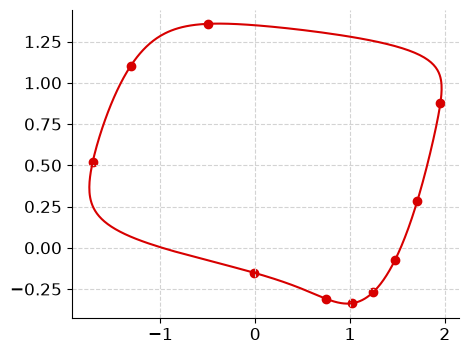

In [3]:
times, points = cycle.sample(512)
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
ax.plot(*points.T)
ax.scatter(*cycle.x0s.T)

In [4]:
for method in ("periodic_schur", "monodromy", "liouville"):
    fl = floquet(cycle, method=method)
    print(method, fl.multipliers, fl.exponents, fl.trivial_error, fl.closure)

periodic_schur [1.00000000e+00 1.69059036e-12] [ 5.39080812e-11 -2.41416251e+00] 6.05273831055797e-10 2.6581664292158038e-11
monodromy [1.00000000e+00 1.69042558e-12] [ 5.31331915e-11 -2.41417119e+00] 5.965734573010195e-10 None
liouville [1.00000000e+00 1.69059036e-12] [ 0.         -2.41416251] None None


In [11]:
isochrons = isochron_foliation(
    cycle,
    jnp.linspace(-jnp.pi, jnp.pi, 6, endpoint=False),
    settings=IsochronSettings(box_scale=2.5),
)

In [12]:
isochrons

IsochronFoliation(cycle=LimitCycle(
  ode=FitzhughNagumo(),
  x0s=f64[10,2],
  period=f64[],
  residual=f64[],
  settle=FixedPoint(
    x=f64[2], tau=weak_f64[], k=1, contraction=weak_f64[], converged=True
  ),
  section=CrossSection(point=f64[2], normal=f64[2]),
  config=SolverConfig(
    solver=Dopri8(),
    rtol=1e-10,
    atol=1e-12,
    max_steps=65536,
    adjoint=ForwardMode()
  )
), isochrons=(Isochron(phase=3.141592653589793, base_point=array([ 1.47374381, -0.0751952 ]), points=array([[ 0.90675809, -0.25837661],
       [ 0.90675515, -0.25837674],
       [ 0.90675117, -0.25837691],
       ...,
       [ 4.70204057,  0.06352123],
       [ 4.72898545,  0.06386611],
       [ 4.75224854,  0.06416084]], shape=(5519, 2)), eta=array([-1.00000000e-06, -9.82508768e-07, -9.59273759e-07, ...,
        3.79996189e-14,  3.90940259e-14,  4.06776278e-14], shape=(5519,)), arclength=array([-2.46990691, -2.46990398, -2.46989999, ...,  3.2331764 ,
        3.26012348,  3.28338845], shape=(5519,)), s

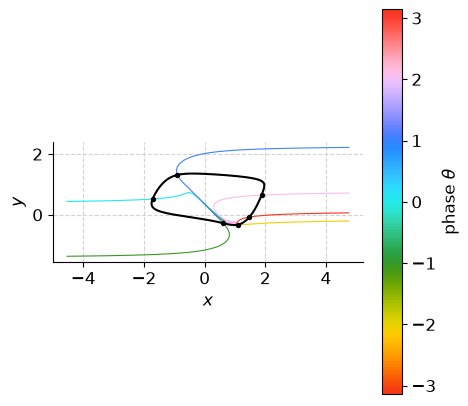

In [18]:
fig = plot_isochrons(isochrons)
# fig.axes[0].set_xlim(0.6, 1.2)
# fig.axes[0].set_ylim(-0.4, 0.0)